# 03 — Feature Selection | Bank Marketing

Escolhe as variáveis que vão para a modelagem passando por quatro filtros, em sequência:

| # | Filtro | Remove | Regra |
|---|---|---|---|
| 1 | Missing | Variáveis com muito nulo/`unknown` antes da imputação | `pct_missing > 70%` |
| 2 | Variância | Variáveis quase constantes | valor mais frequente `≥ 99%` |
| 3 | Colinearidade | Variáveis que repetem a informação de outra | Spearman `> 0,8` (fica a de maior IV) + VIF `> 10` (sai a de menor IV) |
| 4 | Feature importance | Variáveis que não melhoram o modelo | Permutation importance `≤ 0` |

**Tudo é calculado só na base de treino.** Teste (OOS) e OOT não são abertos aqui: se participassem da escolha das variáveis, a avaliação final deixaria de ser honesta.

No filtro 4, o modelo é treinado em 75% do treino e a importância é medida nos outros 25% (uma validação interna, **ainda dentro do treino**).

## 1. Setup e leitura

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
SEED = 42

# Parâmetros dos filtros
LIMITE_MISSING = 0.70
LIMITE_VALOR_FREQUENTE = 0.95
LIMITE_CORRELACAO = 0.80
LIMITE_VIF = 10

In [2]:
from google.colab import drive
drive.mount('/content/drive')
PASTA = r'/content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario'
PASTA_PREP = f'{PASTA}/Base/prep'
PASTA_SAIDA = f'{PASTA}/Base/FeatureSelection'

os.makedirs(PASTA_PREP, exist_ok=True)
os.makedirs(PASTA_SAIDA, exist_ok=True)


TARGET = 'target'
df_treino = pd.read_parquet(f'{PASTA_PREP}/treino.parquet')
transf = joblib.load(f'{PASTA_PREP}/transformadores_prep.joblib')
metadados = transf['metadados_treino']

X = df_treino.drop(columns=[TARGET, 'AnoMes','te_month','te_trimestre', 'cons.conf.idx','cons.price.idx','emp.var.rate','nr.employed','euribor3m'])
y = df_treino[TARGET]
FEATURES_INICIAIS = list(X.columns)

print(f'Treino: {X.shape[0]:,} linhas | {X.shape[1]} variáveis candidatas | conversão {y.mean():.2%}')

Mounted at /content/drive
Treino: 28,823 linhas | 19 variáveis candidatas | conversão 11.27%


In [3]:
# Controle: cada variável recebe o filtro que a removeu (ou fica como selecionada)
controle = pd.DataFrame(index=FEATURES_INICIAIS)
controle.index.name = 'variavel'
controle['removida_em'] = None
controle['motivo'] = None

def remover(variaveis, etapa, motivos):
    for v in variaveis:
        controle.loc[v, ['removida_em', 'motivo']] = [etapa, motivos[v]]

def restantes():
    return controle.index[controle['removida_em'].isna()].tolist()

## 2. Filtro de missing

Depois do Data Prep não sobra nenhum nulo (foram imputados). Por isso usamos o **% de missing medido no treino antes da imputação**, salvo pelo notebook 02 (`metadados_treino`).

Uma variável com mais de 70% imputada é, na prática, quase toda o valor da mediana/moda: a informação real é pequena.

Nulos atuais no treino (deve ser 0): 0


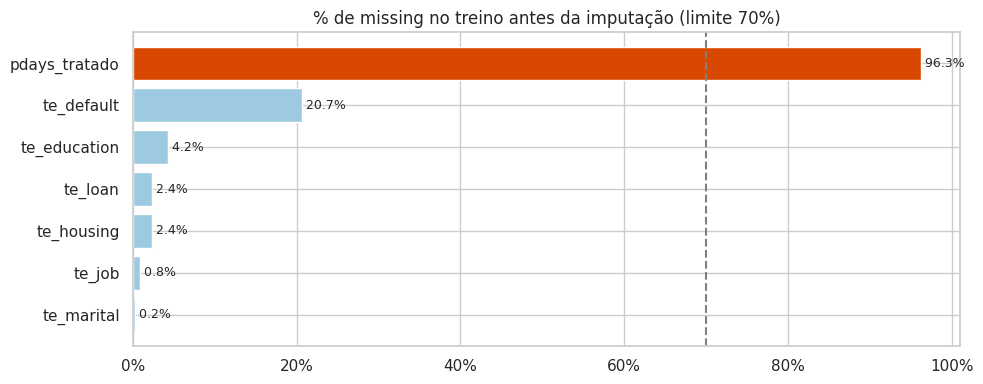

Removidas: ['pdays_tratado']


In [4]:
print('Nulos atuais no treino (deve ser 0):', int(X.isna().sum().sum()))

miss = metadados.loc[FEATURES_INICIAIS, 'pct_missing'].sort_values(ascending=False)
remov_missing = miss[miss > LIMITE_MISSING].index.tolist()
remover(remov_missing, '1_missing', {v: f'{miss[v]:.1%} de missing antes da imputação' for v in remov_missing})

fig, ax = plt.subplots(figsize=(10, 4))
m = miss[miss > 0]
ax.barh(m.index, m.values, color=['#d94801' if v > LIMITE_MISSING else '#9ecae1' for v in m.values])
ax.axvline(LIMITE_MISSING, ls='--', color='grey'); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
for i, v in enumerate(m.values):
    ax.text(v, i, f' {v:.1%}', va='center', fontsize=9)
ax.set_title(f'% de missing no treino antes da imputação (limite {LIMITE_MISSING:.0%})')
plt.tight_layout(); plt.show()

print('Removidas:', remov_missing)

## 3. Filtro de variância (quase constantes)

Como a base está padronizada (desvio = 1 em tudo) e as categóricas viraram Target Encoding, a variância numérica perde o sentido.
Usamos então o **% do valor mais frequente**: se 99% das linhas têm o mesmo valor, a variável quase não diferencia ninguém.

> A medida também vem do `metadados_treino`, calculada antes do encoding.

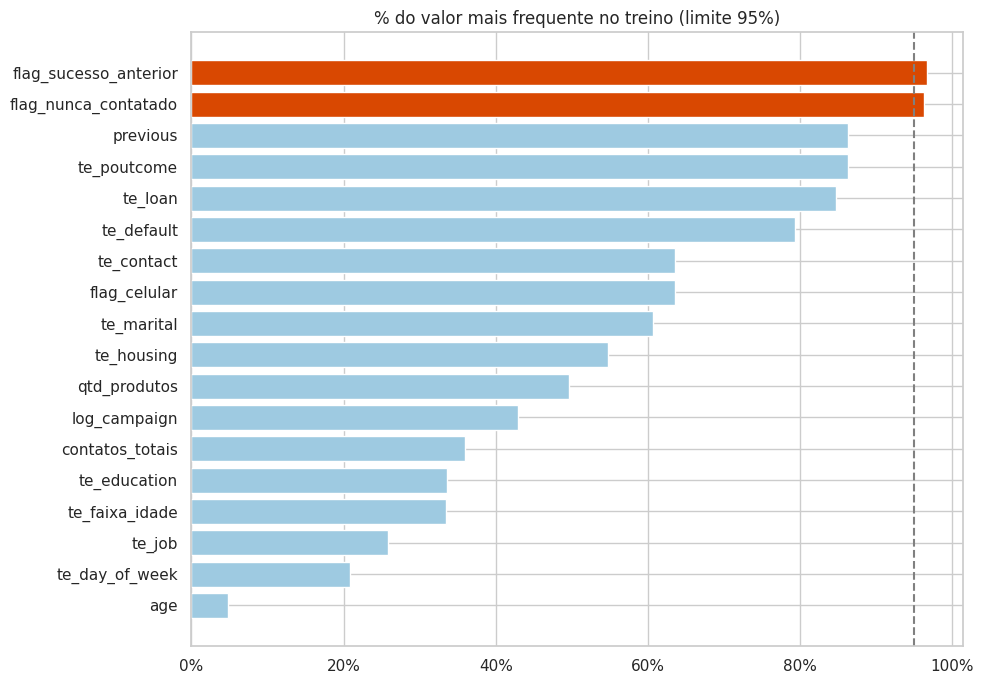

Removidas: ['flag_sucesso_anterior', 'flag_nunca_contatado']


In [5]:
freq = metadados.loc[restantes(), 'pct_valor_mais_frequente'].sort_values(ascending=False)
remov_var = freq[freq >= LIMITE_VALOR_FREQUENTE].index.tolist()
remover(remov_var, '2_variancia', {v: f'{freq[v]:.2%} das linhas com o mesmo valor' for v in remov_var})

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(freq.index, freq.values, color=['#d94801' if v >= LIMITE_VALOR_FREQUENTE else '#9ecae1' for v in freq.values])
ax.axvline(LIMITE_VALOR_FREQUENTE, ls='--', color='grey'); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(f'% do valor mais frequente no treino (limite {LIMITE_VALOR_FREQUENTE:.0%})')
plt.tight_layout(); plt.show()

print('Removidas:', remov_var)

> As flags removidas aqui não perdem informação: `te_poutcome` já separa quem nunca foi contatado (`nonexistent`), quem recusou (`failure`) e quem contratou (`success`) antes.

## 4. Poder individual (IV e AUC univariada)

Não é um filtro: serve de **critério de desempate** na colinearidade (entre duas variáveis parecidas, fica a mais forte).
- **IV:** variável quebrada em até 10 faixas por quantil.
- **AUC univariada:** usa a própria variável como score. Mostramos `max(AUC, 1 − AUC)`, porque o sentido não importa.

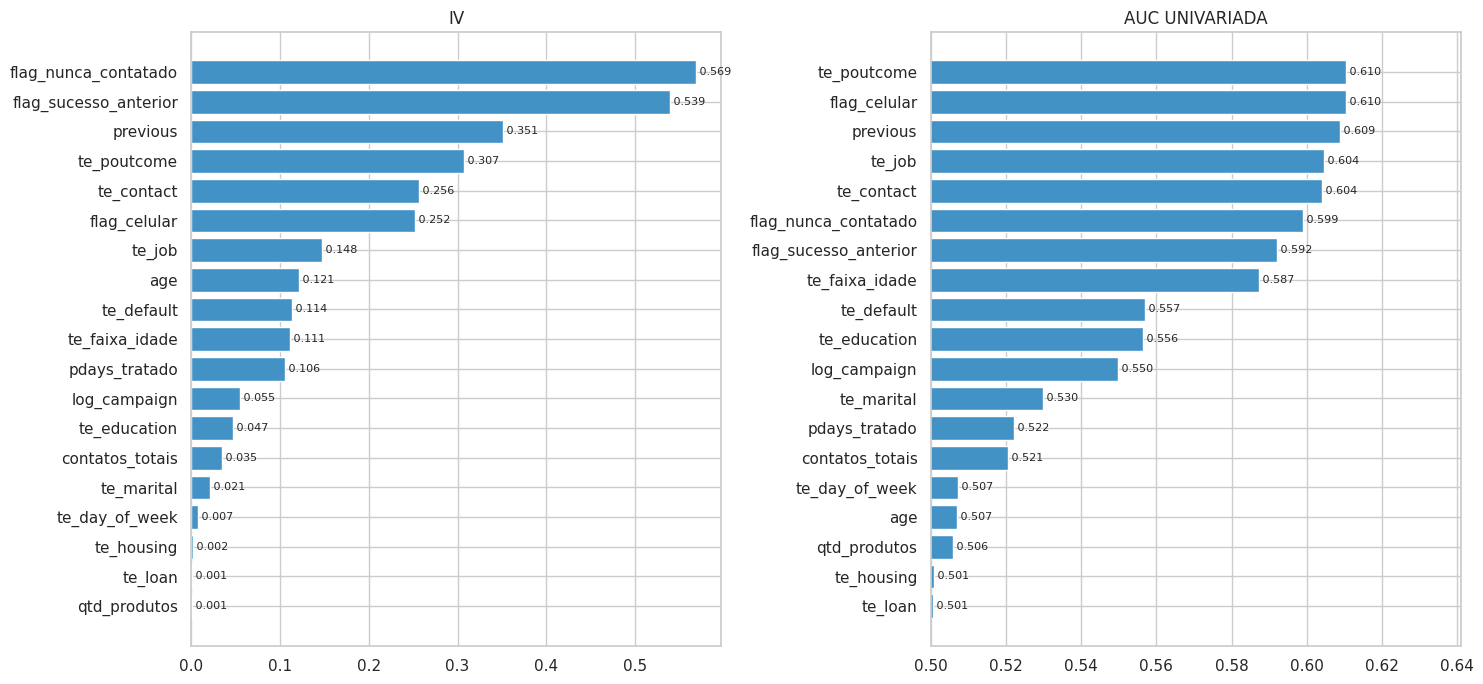

In [6]:
def calc_iv(x, y, q=10, suav=0.5):
    faixas = pd.qcut(x.rank(method='first'), q=min(q, x.nunique()), duplicates='drop') if x.nunique() > q else x
    t = pd.crosstab(faixas, y)
    pct_bons = (t[1] + suav) / (t[1].sum() + suav)
    pct_maus = (t[0] + suav) / (t[0].sum() + suav)
    return float(((pct_bons - pct_maus) * np.log(pct_bons / pct_maus)).sum())

poder = pd.DataFrame({
    'iv': {v: calc_iv(X[v], y) for v in FEATURES_INICIAIS},
    'auc_univariada': {v: max(roc_auc_score(y, X[v]), 1 - roc_auc_score(y, X[v])) for v in FEATURES_INICIAIS},
})
controle = controle.join(poder)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, col in zip(axes, ['iv', 'auc_univariada']):
    s = poder[col].sort_values()
    ax.barh(s.index, s.values, color='#4292c6')
    for i, v in enumerate(s.values):
        ax.text(v, i, f' {v:.3f}', va='center', fontsize=8)
    ax.set_title(col.upper().replace('_', ' '))
axes[1].set_xlim(0.5, None)
plt.tight_layout(); plt.show()

## 5. Filtro de colinearidade

**5.1 Pares muito correlacionados.** Para cada par com |Spearman| > 0,8, sai a variável de **menor IV**. Os pares são avaliados do mais correlacionado para o menos.

**5.2 VIF.** Pega colinearidade "escondida", em que uma variável é explicada por uma combinação de várias outras. Enquanto houver VIF > 10, sai, uma por vez, a variável de **menor IV entre as que estão acima do limite**. Assim a colinearidade é resolvida sem jogar fora a variável mais forte do grupo.

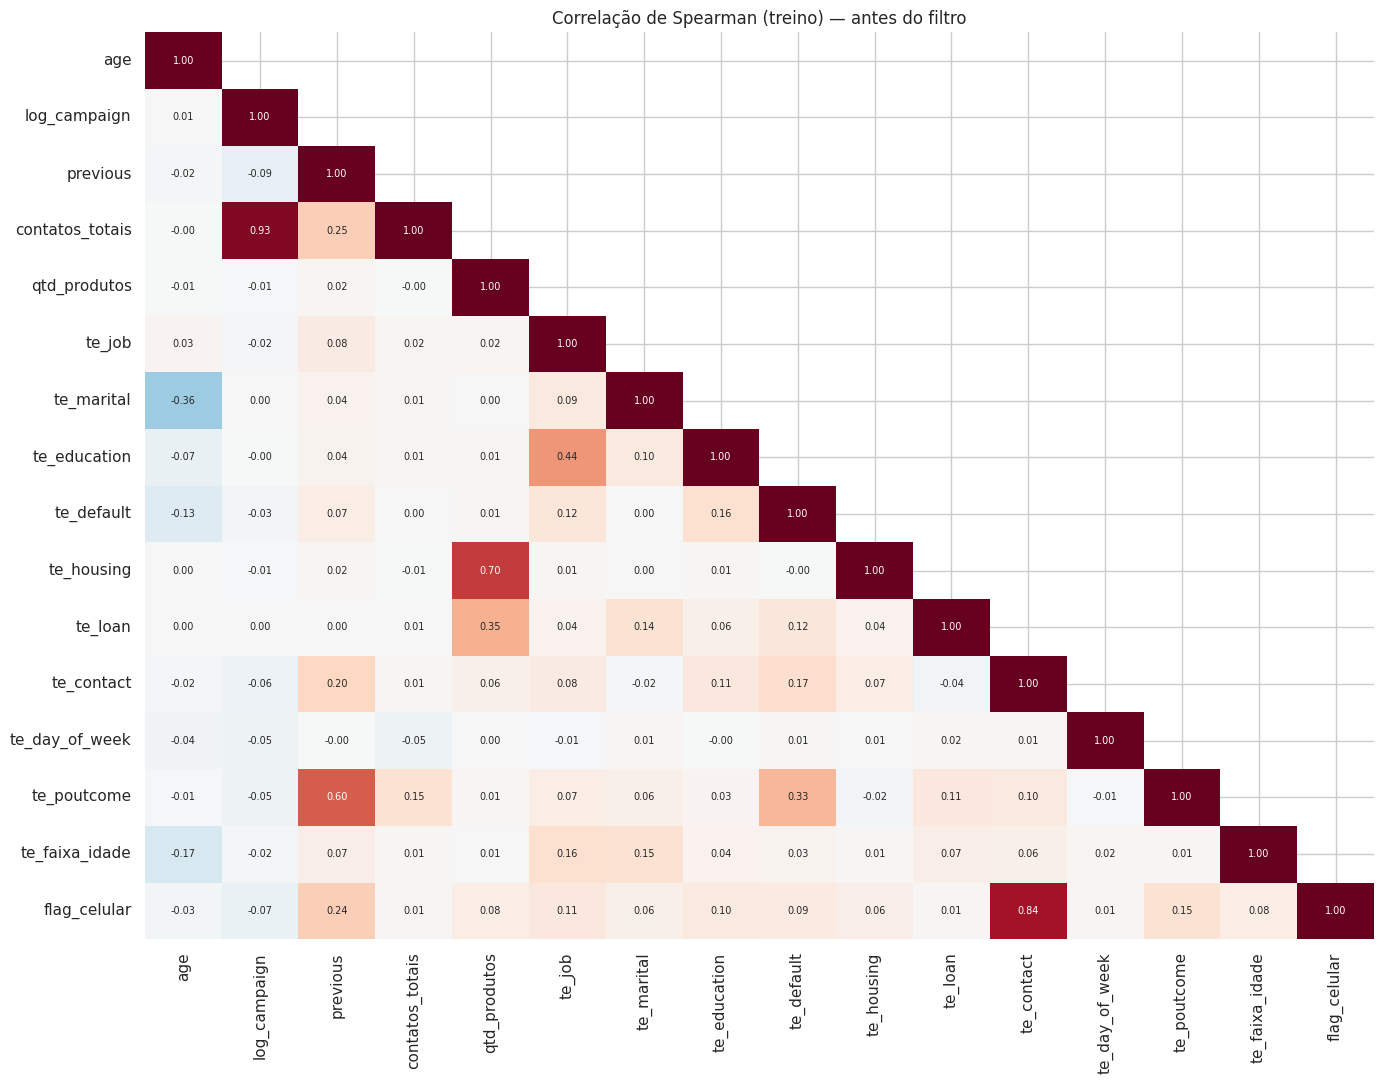

In [7]:
vars_atual = restantes()
corr = X[vars_atual].corr(method='spearman')

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            cbar=False, annot_kws={'size': 7})
plt.title('Correlação de Spearman (treino) — antes do filtro'); plt.tight_layout(); plt.show()

In [8]:
# 5.1 Pares acima do limite
pares = (corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename('spearman_abs').reset_index()
             .rename(columns={'level_0': 'var_1', 'level_1': 'var_2'}))
pares = pares[pares['spearman_abs'] > LIMITE_CORRELACAO].sort_values('spearman_abs', ascending=False)

removidas_corr, motivos_corr, log_pares = [], {}, []
for _, r in pares.iterrows():
    a, b = r['var_1'], r['var_2']
    if a in removidas_corr or b in removidas_corr:
        decisao = 'par já resolvido'
    else:
        fica, sai = (a, b) if poder.loc[a, 'iv'] >= poder.loc[b, 'iv'] else (b, a)
        removidas_corr.append(sai)
        motivos_corr[sai] = f'corr {r["spearman_abs"]:.2f} com {fica} (IV {poder.loc[sai, "iv"]:.3f} < {poder.loc[fica, "iv"]:.3f})'
        decisao = f'sai {sai}'
    log_pares.append({'var_1': a, 'iv_1': poder.loc[a, 'iv'], 'var_2': b, 'iv_2': poder.loc[b, 'iv'],
                      'spearman_abs': r['spearman_abs'], 'decisao': decisao})

remover(removidas_corr, '3a_correlacao', motivos_corr)
pd.DataFrame(log_pares)

,var_1,iv_1,var_2,iv_2,spearman_abs,decisao
0,log_campaign,0.0549,contatos_totais,0.0348,0.9255,sai contatos_totais
1,te_contact,0.2561,flag_celular,0.2525,0.8388,sai flag_celular


In [9]:
# 5.2 VIF iterativo
def tabela_vif(df_x):
    mat = np.column_stack([np.ones(len(df_x)), df_x.values])     # constante para o VIF ficar correto
    return pd.Series([variance_inflation_factor(mat, i + 1) for i in range(df_x.shape[1])],
                     index=df_x.columns).sort_values(ascending=False)

vars_vif = restantes()
historico_vif, motivos_vif = [], {}
while True:
    vif = tabela_vif(X[vars_vif])
    acima = vif[vif > LIMITE_VIF]
    if acima.empty:
        break
    sai = poder.loc[acima.index, 'iv'].idxmin()          # entre as de VIF alto, sai a mais fraca
    historico_vif.append({'removida': sai, 'vif': vif[sai], 'iv': poder.loc[sai, 'iv'],
                          'outras_acima_do_limite': ', '.join(acima.index.drop(sai))})
    motivos_vif[sai] = f'VIF {vif[sai]:.1f} > {LIMITE_VIF} (menor IV do grupo)'
    vars_vif.remove(sai)

remover(list(motivos_vif), '3b_vif', motivos_vif)
print('Removidas por VIF:', pd.DataFrame(historico_vif).to_string(index=False) if historico_vif else 'nenhuma')
print('\nVIF final:')
vif.to_frame('vif')

Removidas por VIF: nenhuma

VIF final:


,vif
qtd_produtos,4.5507
te_housing,3.2735
te_loan,2.1920
previous,1.7040
te_poutcome,1.6586
age,1.3580
te_job,1.3290
te_marital,1.2950
te_faixa_idade,1.2905
te_education,1.1065


## 6. Filtro de feature importance

1. Treinamos um Random Forest em 75% do treino.
2. Nos outros 25% (validação interna), medimos a **permutation importance**: quanto a AUC cai quando embaralhamos cada variável (10 repetições).
3. Sai toda variável com importância **≤ 0**: embaralhá-la não piora (ou até melhora) o modelo, ou seja, ela não ajuda.

Incluímos também uma coluna de **ruído aleatório** como referência visual: ela mostra o tamanho da importância que aparece só por acaso. Variáveis perto dela merecem desconfiança, mas a regra de corte é o zero. Cortar exatamente no ruído é agressivo demais numa base com sinal fraco como esta (o sanity check da seção 7.1 mostra isso).

Por que permutation e não a importância padrão (Gini) do Random Forest? A Gini favorece variáveis contínuas com muitos valores, e mede o ajuste no próprio dado de treino do modelo. A permutation mede a contribuição real em dados que o modelo não viu. A Gini aparece no gráfico só para comparação.

In [10]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold

vars_fi = restantes()
rng = np.random.RandomState(SEED)
X_fi = X[vars_fi].copy()
X_fi['ruido_aleatorio'] = rng.normal(size=len(X_fi))

params_fi = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, max_depth=4, min_child_samples=100,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                 random_state=SEED, verbose=-1)

# Permutation importance repetida nos 5 folds (cada fold valida em dados que o modelo não viu)
skf_fi = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
perm_folds, gain_folds, auc_folds = [], [], []
for k, (idx_fit, idx_val) in enumerate(skf_fi.split(X_fi, y)):
    X_fit, X_val = X_fi.iloc[idx_fit], X_fi.iloc[idx_val]
    y_fit, y_val = y.iloc[idx_fit], y.iloc[idx_val]
    lgbm_fi = LGBMClassifier(**params_fi).fit(X_fit, y_fit)
    auc_folds.append(roc_auc_score(y_val, lgbm_fi.predict_proba(X_val)[:, 1]))
    perm = permutation_importance(lgbm_fi, X_val, y_val, scoring='roc_auc', n_repeats=5,
                                  random_state=SEED + k, n_jobs=-1)
    perm_folds.append(pd.Series(perm.importances_mean, index=X_fi.columns))
    gain_folds.append(pd.Series(lgbm_fi.booster_.feature_importance(importance_type='gain'), index=X_fi.columns))

perm_folds = pd.concat(perm_folds, axis=1)
gain = pd.concat(gain_folds, axis=1).mean(axis=1)
print(f'AUC do LightGBM na validação (média dos 5 folds): {np.mean(auc_folds):.4f} ± {np.std(auc_folds):.4f}')

imp = pd.DataFrame({
    'perm_importance': perm_folds.mean(axis=1),            # média dos 5 folds
    'perm_std': perm_folds.std(axis=1),                    # variação entre os folds
    'folds_com_ganho': (perm_folds > 0).sum(axis=1),       # em quantos folds a variável ajudou (0 a 5)
    'gini_importance': gain / gain.sum(),                  # ganho (gain) do LightGBM, normalizado — só referência
}).sort_values('perm_importance', ascending=False)
imp

AUC do LightGBM na validação (média dos 5 folds): 0.7351 ± 0.0086


,perm_importance,perm_std,folds_com_ganho,gini_importance
te_contact,0.0503,0.0087,5,0.1102
te_poutcome,0.0335,0.0043,5,0.4126
te_default,0.0173,0.0017,5,0.0371
age,0.0147,0.0016,5,0.1059
log_campaign,0.0122,0.0019,5,0.0361
te_job,0.0061,0.0008,5,0.0676
previous,0.0049,0.0015,5,0.0467
te_education,0.0031,0.0028,4,0.0342
te_day_of_week,0.0018,0.0008,5,0.0234
te_faixa_idade,0.0012,0.0017,3,0.0333


In [11]:
corte_ruido = imp.loc['ruido_aleatorio', 'perm_importance']
MIN_FOLDS = 3       # precisa ajudar na maioria dos 5 folds
sem_ganho = imp.index[((imp['perm_importance'] <= 0) | (imp['folds_com_ganho'] < MIN_FOLDS))
                      & (imp.index != 'ruido_aleatorio')].tolist()
remover(sem_ganho, '4_feature_importance',
        {v: f'perm média {imp.loc[v, "perm_importance"]:.5f}, ajudou em {imp.loc[v, "folds_com_ganho"]} de 5 folds' for v in sem_ganho})
controle = controle.join(imp[['perm_importance', 'folds_com_ganho', 'gini_importance']])

print('Removidas por importância:', sem_ganho)
print('Abaixo do ruído, mas mantidas (atenção na modelagem):',
      imp.index[(imp['perm_importance'] <= corte_ruido) & ~imp.index.isin(sem_ganho + ['ruido_aleatorio'])].tolist())

Removidas por importância: ['te_housing', 'qtd_produtos']
Abaixo do ruído, mas mantidas (atenção na modelagem): []


## 7. Resultado da seleção

In [12]:
SELECIONADAS = restantes()
controle['selecionada'] = controle['removida_em'].isna()

ordem = {'1_missing': 1, '2_variancia': 2, '3a_correlacao': 3, '3b_vif': 4, '4_feature_importance': 5}
tabela_final = controle.assign(_o=controle['removida_em'].map(ordem).fillna(0)) \
                       .sort_values(['_o', 'iv'], ascending=[True, False]).drop(columns='_o')

print(f'{len(FEATURES_INICIAIS)} variáveis candidatas → {len(SELECIONADAS)} selecionadas\n')
tabela_final.style.format({'iv': '{:.4f}', 'auc_univariada': '{:.4f}', 'perm_importance': '{:.5f}',
                           'gini_importance': '{:.4f}'}, na_rep='—') \
    .apply(lambda r: ['background-color: #e5f5e0' if r['selecionada'] else '' for _ in r], axis=1)

19 variáveis candidatas → 12 selecionadas



,removida_em,motivo,iv,auc_univariada,perm_importance,folds_com_ganho,gini_importance,selecionada
variavel,,,,,,,,
previous,—,—,0.3510,0.6088,0.00489,5.000000,0.0467,True
te_poutcome,—,—,0.3075,0.6105,0.03352,5.000000,0.4126,True
te_contact,—,—,0.2561,0.6041,0.05029,5.000000,0.1102,True
te_job,—,—,0.1476,0.6045,0.00608,5.000000,0.0676,True
age,—,—,0.1214,0.5071,0.01472,5.000000,0.1059,True
te_default,—,—,0.1135,0.5570,0.01732,5.000000,0.0371,True
te_faixa_idade,—,—,0.1108,0.5873,0.00122,3.000000,0.0333,True
log_campaign,—,—,0.0549,0.5499,0.01220,5.000000,0.0361,True
te_education,—,—,0.0466,0.5564,0.00305,4.000000,0.0342,True


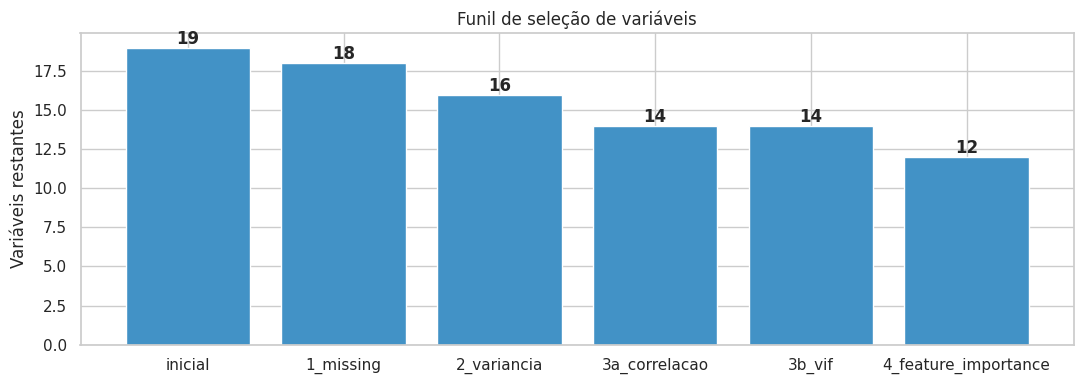

In [13]:
# Funil da seleção
etapas = ['inicial', '1_missing', '2_variancia', '3a_correlacao', '3b_vif', '4_feature_importance']
qtd, n = [], len(FEATURES_INICIAIS)
for e in etapas:
    n -= 0 if e == 'inicial' else (controle['removida_em'] == e).sum()
    qtd.append(n)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(etapas, qtd, color='#4292c6')
for i, v in enumerate(qtd):
    ax.text(i, v, str(v), ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('Variáveis restantes'); ax.set_title('Funil de seleção de variáveis')
plt.tight_layout(); plt.show()

### 7.1 Sanity check: a seleção não piorou o modelo?

Comparamos a AUC na mesma validação interna (25% do treino) usando **todas** as variáveis contra **só as selecionadas**. O esperado é uma AUC parecida com menos variáveis.

In [14]:
idx_fit, idx_val = train_test_split(X.index, test_size=0.25, stratify=y, random_state=SEED)
resultado = []
for nome_modelo, modelo in [
        ('Regressão Logística', LogisticRegression(max_iter=2000, class_weight='balanced')),
        ('Random Forest', RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=50,
                                                  class_weight='balanced', n_jobs=-1, random_state=SEED))]:
    for conjunto, cols in [('todas', FEATURES_INICIAIS), ('selecionadas', SELECIONADAS)]:
        modelo.fit(X.loc[idx_fit, cols], y.loc[idx_fit])
        auc = roc_auc_score(y.loc[idx_val], modelo.predict_proba(X.loc[idx_val, cols])[:, 1])
        resultado.append({'modelo': nome_modelo, 'conjunto': conjunto, 'qtd_variaveis': len(cols), 'auc_validacao_interna': auc})
pd.DataFrame(resultado).pivot(index='modelo', columns='conjunto', values='auc_validacao_interna')

conjunto,selecionadas,todas
modelo,,
Random Forest,0.7498,0.7468
Regressão Logística,0.7437,0.7482


## 8. Salvar a lista de variáveis

In [15]:
with open(f'{PASTA_PREP}/variaveis_selecionadas.json', 'w') as f:
    json.dump(SELECIONADAS, f, indent=2)
tabela_final.to_csv(f'{PASTA_PREP}/tabela_selecao_variaveis.csv')

print('Salvo em', PASTA_SAIDA)
print(f'\nVariáveis selecionadas ({len(SELECIONADAS)}):')
for v in SELECIONADAS:
    print(' -', v)

Salvo em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Base/FeatureSelection

Variáveis selecionadas (12):
 - age
 - log_campaign
 - previous
 - te_job
 - te_marital
 - te_education
 - te_default
 - te_loan
 - te_contact
 - te_day_of_week
 - te_poutcome
 - te_faixa_idade


**Como usar na modelagem (notebook 04):**

```python
with open(f'{PASTA_PREP}/variaveis_selecionadas.json') as f:
    FEATURES = json.load(f)

X_treino = pd.read_parquet(f'{PASTA_PREP}/treino.parquet')[FEATURES]
X_teste  = pd.read_parquet(f'{PASTA_PREP}/teste.parquet')[FEATURES]
X_oot    = pd.read_parquet(f'{PASTA_PREP}/oot.parquet')[FEATURES]
```